[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# A seasonal peak needs a spatial denominator

When does modeled abundance peak in our selected region—and how much of that region has a prediction? We inspect the seasonal geometry, calculate weekly coverage, and reconcile a SQL peak with the worker’s `migration_calendar`. Then we move one boundary and repeat the calculation.

**Public model sample, no access key:** this notebook uses Cornell’s **Yellow-bellied Sapsucker in Michigan** example. It is not duck data. The duck worker supports this sample to demonstrate the same GeoPackage and GeoTIFF readers used by authenticated duck products. The existing [Virginia duck analysis](spatial-migration.ipynb) remains a separate example requiring `EBIRDST_KEY`.

These are **2023 model estimates**, not sightings, live migration tracks or a current forecast. The worker downloads the public sample from [Cornell’s repository at commit a3ab944…](https://github.com/ebird/ebirdst_example-data/tree/a3ab944f505ad6f583e0c830d5e951929446e9eb). The official [data-product guide](https://ebird.github.io/ebirdst/articles/status.html) explains the sample and the standardized relative-abundance units.

## Choose a region

`WEST_LONGITUDE` sets the west edge of a rectangular WGS84 study region; longitude is in decimal degrees, east-positive. The other edges stay at 82°W, 41°N and 49°N. Default **−90** uses the broad window; experiment **−86** retains its eastern part. Accepted values range from −90 through −84. This is a study window around Michigan, not a state boundary. Restart and run all after editing.

In [1]:
WEST_LONGITUDE = -90  # decimal degrees; -90 <= value <= -84; experiment: -86

In [2]:
import os
from datetime import UTC, datetime

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

from notebook_support import COLORS, finish, polygon, prose, theme

if isinstance(WEST_LONGITUDE, bool) or not isinstance(WEST_LONGITUDE, (int, float)) or not -90 <= WEST_LONGITUDE <= -84:
    raise ValueError("WEST_LONGITUDE must be a finite number from -90 through -84.")
for key in ("DUCKS_EBIRD_BASE_URL", "DUCKS_STATUS_BASE_URL", "DUCKS_STATUS_SAMPLE_BASE_URL"):
    os.environ.pop(key, None)
run_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ducks/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ducks/notebooks/pyproject.toml.

## Attach the release and load spatial SQL

Both the native worker and the SQL extensions are published artifacts. The literal release location needs no local Bun installation or source checkout. The helper clears fixture endpoint overrides; all worker data calls below use Cornell’s pinned public sample. No credential or replay mode is needed. See the [README](README.md) for the independent notebook environment.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial FROM core;
LOAD spatial;
SET geometry_always_xy = true;
ATTACH 'ducks' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-ducks@v0.1.1');

,Success


## Retrieve a single region and its seasonal ranges

The weekly table retains the requested region geometry and its native grid counts. We materialize worker calls once before local SELECT capture, preventing display machinery from repeating downloads. `migration_calendar` is intentionally a second source calculation for the peak comparison; it reads the same pinned product, not an independent dataset.

In [4]:
%%sql
CREATE TABLE weekly_source AS
SELECT * FROM ducks.main.weekly_abundance(
    'yebsap-example',
    'POLYGON(({{WEST_LONGITUDE}} 41,-82 41,-82 49,{{WEST_LONGITUDE}} 49,{{WEST_LONGITUDE}} 41))',
    data_year := 2023, resolution := '27km'
);
CREATE TABLE peak_source AS
SELECT * FROM ducks.main.migration_calendar(
    'yebsap-example',
    'POLYGON(({{WEST_LONGITUDE}} 41,-82 41,-82 49,{{WEST_LONGITUDE}} 49,{{WEST_LONGITUDE}} 41))',
    data_year := 2023, resolution := '27km'
);
CREATE TABLE range_source AS
SELECT * FROM ducks.main.seasonal_ranges('yebsap-example', data_year := 2023, resolution := '27km');
SELECT DISTINCT species_code, product_species_code, prediction_year, resolution_km,
       geometry_crs, source_product FROM weekly_source;

,species_code,product_species_code,prediction_year,resolution_km,geometry_crs,source_product
0,yebsap,yebsap-example,2023,27,EPSG:4326,2023/yebsap-example/weekly/yebsap-example_abun...


In [5]:
prose(
    f"Public sample queried at **{run_utc}**. The model year is **2023**, "
    "independent of the retrieval date. The 27 km grid is read at its native resolution; "
    "the notebook performs no interpolation or upsampling."
)

Public sample queried at **2026-11-14T06:14:01+00:00**. The model year is **2023**, independent of the retrieval date. The 27 km grid is read at its native resolution; the notebook performs no interpolation or upsampling.

## Map the window against the seasonal geometry

SQL converts WKB to geometry and clips each seasonal range to the requested window. The range geometry is an occurrence envelope, not an abundance surface or a raster coverage mask. A pale range outside the window helps show what the parameter excludes. We do not calculate areas in longitude/latitude degrees.

In [6]:
%%sql
CREATE TABLE region AS
SELECT ST_GeomFromWKB(first(region_wkb)) AS geom FROM weekly_source;
CREATE TABLE range_map AS
SELECT season, start_date, end_date, wraps_year,
       ST_AsGeoJSON(ST_GeomFromWKB(geometry_wkb)) AS range_geojson,
       ST_AsGeoJSON(ST_Intersection(ST_GeomFromWKB(geometry_wkb), region.geom)) AS clipped_geojson,
       ST_AsGeoJSON(region.geom) AS region_geojson,
       ST_Intersects(ST_GeomFromWKB(geometry_wkb), region.geom) AS intersects
FROM range_source CROSS JOIN region;

,Count


In [7]:
%%sql ranges <<
SELECT * FROM range_map ORDER BY start_date;

In [8]:
display(ranges[["season", "start_date", "end_date", "wraps_year", "intersects"]])

,season,start_date,end_date,wraps_year,intersects
0,prebreeding_migration,2023-03-15,2023-05-10,False,True
1,breeding,2023-05-17,2023-08-16,False,True
2,postbreeding_migration,2023-08-23,2023-11-15,False,True
3,nonbreeding,2023-11-22,2023-03-08,True,True


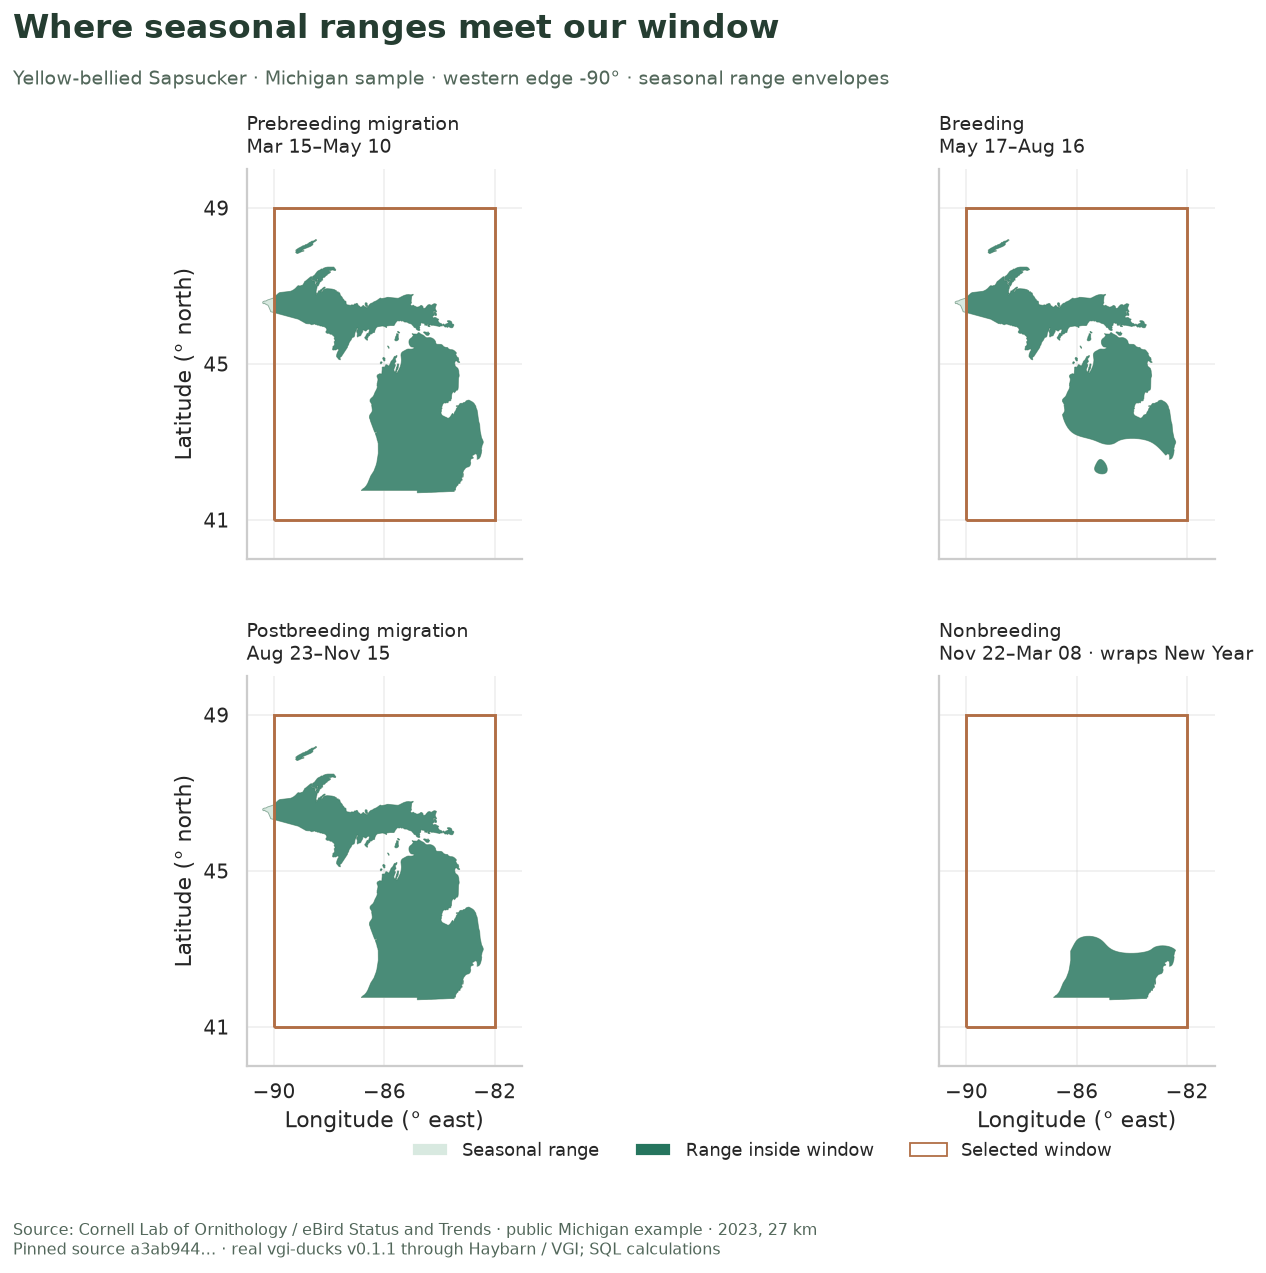

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, (_, row) in zip(axes.flat, ranges.iterrows(), strict=True):
    polygon(ax, row.range_geojson, facecolor="#d8e9e0", edgecolor="#8cad9c", linewidth=0.5)
    polygon(ax, row.clipped_geojson, facecolor=COLORS["modeled"], edgecolor="none", alpha=0.8)
    polygon(ax, row.region_geojson, facecolor="none", edgecolor=COLORS["shortcut"], linewidth=1.6)
    title = row.season.replace("_", " ").capitalize()
    dates = f"{pd.Timestamp(row.start_date):%b %d}–{pd.Timestamp(row.end_date):%b %d}"
    ax.set_title(
        f"{title}\n{dates}" + (" · wraps New Year" if row.wraps_year else ""), loc="left", fontsize=10.5, pad=9
    )
    ax.set_xlim(-91, -81)
    ax.set_ylim(40, 50)
    ax.set_aspect(1 / np.cos(np.deg2rad(45)))
    ax.set_xticks([-90, -86, -82])
    ax.set_yticks([41, 45, 49])
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("Longitude (° east)")
for ax in axes[:, 0]:
    ax.set_ylabel("Latitude (° north)")
fig.legend(
    handles=[
        Patch(facecolor="#d8e9e0", label="Seasonal range"),
        Patch(facecolor=COLORS["modeled"], label="Range inside window"),
        Patch(facecolor="none", edgecolor=COLORS["shortcut"], label="Selected window"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.55, 0.085),
    ncol=3,
    frameon=False,
    fontsize=10,
)
fig.subplots_adjust(left=0.12, right=0.94, bottom=0.17, top=0.86, hspace=0.30, wspace=0.18)
finish(
    fig,
    "Where seasonal ranges meet our window",
    f"Yellow-bellied Sapsucker · Michigan sample · western edge {WEST_LONGITUDE}° · seasonal range envelopes",
    f"ranges-west-{WEST_LONGITUDE}.png",
)

## Keep NoData out of the abundance denominator

The worker selects **grid-cell centers strictly inside the polygon and within the raster extent**. Its mean weights the selected cells with finite predictions equally, including true zeros. `coverage_fraction` is modeled cells divided by selected cells; it is not the fraction of the entire polygon’s geographic area. NoData cells are excluded, and no modeled cells yields NULL.

For a diagnostic contrast, SQL also calculates what the mean would become if those unmodeled selected cells were assigned zero. That shortcut is deliberately labeled: it asserts absence where the model supplied no estimate. Both the valid mean and the shortcut have relative-abundance units, not population counts.

In [10]:
%%sql
CREATE TABLE weekly AS
SELECT *, CAST(week_date AS DATE) AS model_week,
       100.0 * modeled_cell_count / nullif(selected_cell_count, 0) AS coverage_percent,
       mean_relative_abundance * modeled_cell_count / nullif(selected_cell_count, 0) AS zero_filled_shortcut,
       mean_relative_abundance > 0 AND mean_relative_abundance = max(mean_relative_abundance) OVER () AS is_peak
FROM weekly_source;

,Count


In [11]:
%%sql weekly <<
SELECT model_week, mean_relative_abundance, max_relative_abundance,
       selected_cell_count, modeled_cell_count, coverage_fraction, coverage_percent,
       zero_filled_shortcut, is_peak
FROM weekly ORDER BY model_week;

In [12]:
display(weekly.head(6).round(5))

,model_week,mean_relative_abundance,max_relative_abundance,selected_cell_count,modeled_cell_count,coverage_fraction,coverage_percent,zero_filled_shortcut,is_peak
0,2023-01-04,0.00140,0.03174,779,289,0.37099,37.09884,0.00052,False
1,2023-01-11,0.00156,0.03440,779,289,0.37099,37.09884,0.00058,False
2,2023-01-18,0.00157,0.03396,779,289,0.37099,37.09884,0.00058,False
3,2023-01-25,0.00153,0.03387,779,289,0.37099,37.09884,0.00057,False
4,2023-02-01,0.00151,0.03163,779,289,0.37099,37.09884,0.00056,False
5,2023-02-08,0.00148,0.04130,779,289,0.37099,37.09884,0.00055,False


## Validate the counts and the peak

Check unique model weeks, nonnegative values, coverage arithmetic, NULL semantics and geometry validity. Compare the **sets** of positive peak weeks so ties remain valid. A zero-only or unavailable series has no positive peak. The checks do not demand a particular date or a hardcoded number of rows.

In [13]:
%%sql checks <<
SELECT 'unique model weeks' AS check_name, count(*) > 0 AND count(*) = count(DISTINCT model_week) AS passed FROM weekly
UNION ALL SELECT 'count bounds', bool_and(0 <= modeled_cell_count AND modeled_cell_count <= selected_cell_count) FROM weekly
UNION ALL SELECT 'coverage arithmetic', bool_and(CASE WHEN selected_cell_count = 0 THEN coverage_fraction IS NULL
    ELSE abs(coverage_fraction - modeled_cell_count * 1.0 / selected_cell_count) < 1e-12 END) FROM weekly
UNION ALL SELECT 'NULL means no modeled cells', bool_and((mean_relative_abundance IS NULL) = (modeled_cell_count = 0)) FROM weekly
UNION ALL SELECT 'mean and maximum bounds', bool_and(coalesce(
    mean_relative_abundance >= 0 AND mean_relative_abundance <= max_relative_abundance, modeled_cell_count = 0)) FROM weekly
UNION ALL SELECT 'valid region and range geometries',
    (SELECT bool_and(ST_IsValid(geom)) FROM region) AND
    (SELECT bool_and(ST_IsValid(ST_GeomFromWKB(geometry_wkb))) FROM range_source)
UNION ALL SELECT 'worker and SQL positive peak sets agree', NOT EXISTS (
    (SELECT model_week FROM weekly WHERE is_peak EXCEPT SELECT CAST(week_date AS DATE) FROM peak_source)
    UNION ALL
    (SELECT CAST(week_date AS DATE) FROM peak_source EXCEPT SELECT model_week FROM weekly WHERE is_peak)
)
UNION ALL SELECT 'window metadata agrees', bool_and(product_species_code = 'yebsap-example'
    AND prediction_year = 2023 AND resolution_km = 27 AND geometry_crs = 'EPSG:4326') FROM weekly_source;

In [14]:
display(checks)
assert checks.passed.fillna(False).all(), "Source or aggregation invariant failed."
prose(
    f"All **{len(checks)} checks** pass across **{len(weekly)} returned weeks**. "
    "The worker’s peak-week set agrees with SQL. That agreement verifies the implementation "
    "against the same source product; it is not independent ecological validation."
)

,check_name,passed
0,unique model weeks,True
1,count bounds,True
2,coverage arithmetic,True
3,NULL means no modeled cells,True
4,mean and maximum bounds,True
5,valid region and range geometries,True
6,worker and SQL positive peak sets agree,True
7,window metadata agrees,True


All **8 checks** pass across **52 returned weeks**. The worker’s peak-week set agrees with SQL. That agreement verifies the implementation against the same source product; it is not independent ecological validation.

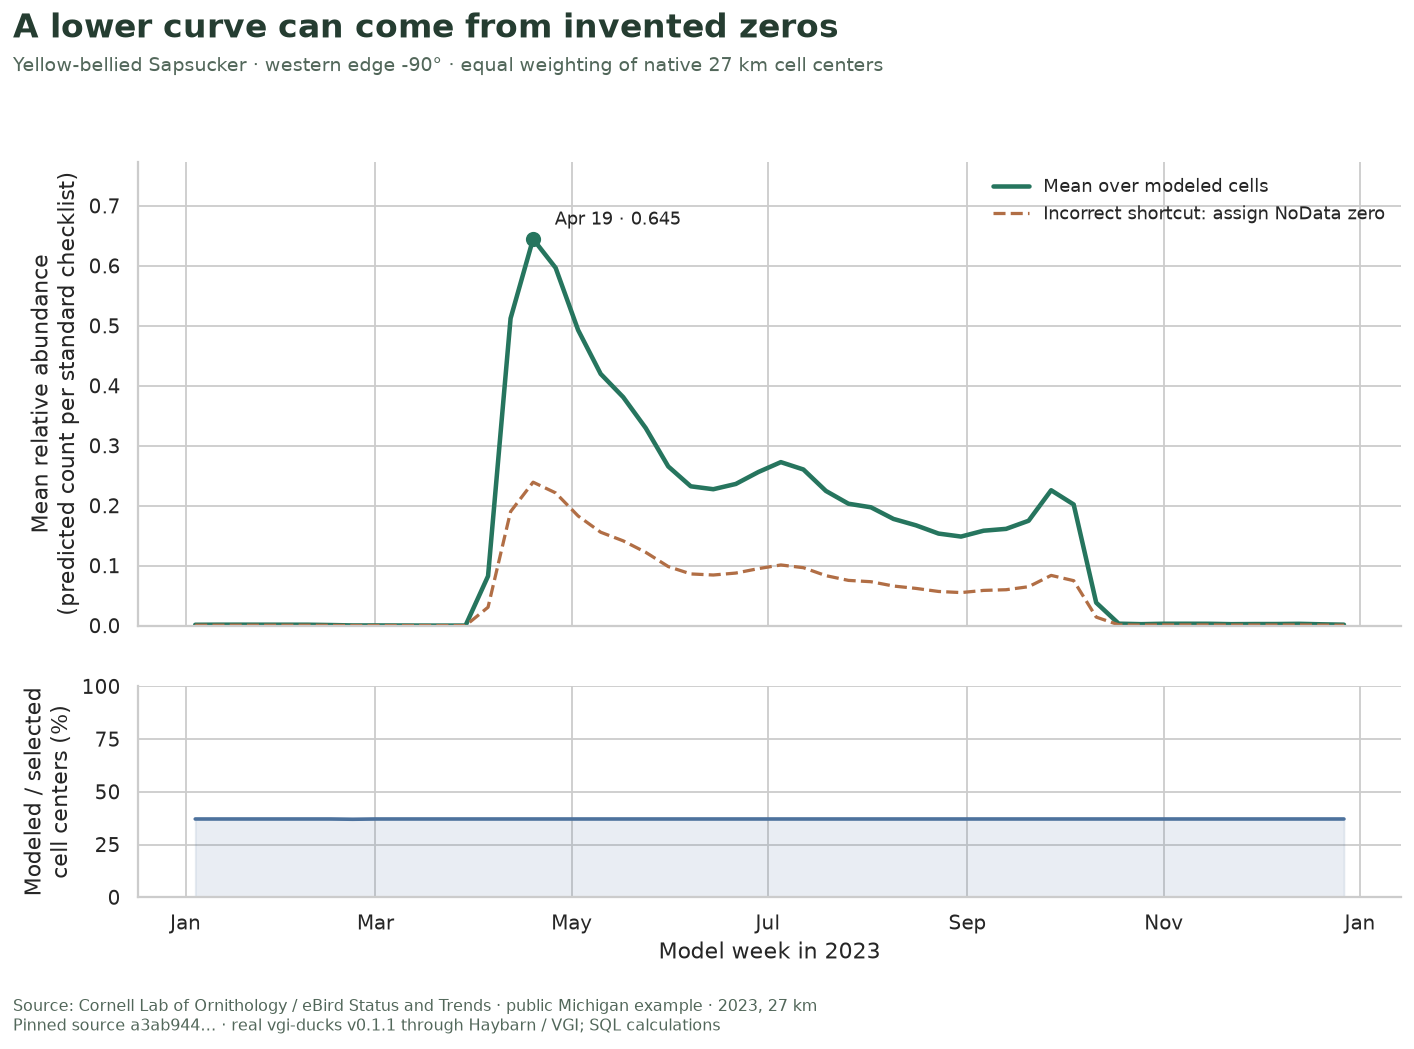

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax, coverage_ax = axes
ax.plot(
    weekly.model_week,
    weekly.mean_relative_abundance,
    color=COLORS["modeled"],
    linewidth=2.5,
    label="Mean over modeled cells",
)
ax.plot(
    weekly.model_week,
    weekly.zero_filled_shortcut,
    color=COLORS["shortcut"],
    linewidth=1.8,
    linestyle="--",
    label="Incorrect shortcut: assign NoData zero",
)
peaks = weekly.loc[weekly.is_peak]
ax.scatter(peaks.model_week, peaks.mean_relative_abundance, color=COLORS["modeled"], s=55, zorder=4)
for row in peaks.itertuples():
    ax.annotate(
        f"{row.model_week:%b %d} · {row.mean_relative_abundance:.3f}",
        (row.model_week, row.mean_relative_abundance),
        xytext=(12, 8),
        textcoords="offset points",
        fontsize=10,
    )
ax.set_ylabel("Mean relative abundance\n(predicted count per standard checklist)")
ax.set_ylim(bottom=0, top=weekly.mean_relative_abundance.max() * 1.20)
ax.legend(loc="upper right", frameon=False, fontsize=10)
coverage_ax.plot(weekly.model_week, weekly.coverage_percent, color=COLORS["coverage"], linewidth=2)
coverage_ax.fill_between(weekly.model_week, 0, weekly.coverage_percent, color=COLORS["coverage"], alpha=0.12)
coverage_ax.set_ylabel("Modeled / selected\ncell centers (%)")
coverage_ax.set_ylim(0, 100)
coverage_ax.set_yticks([0, 25, 50, 75, 100])
coverage_ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
coverage_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
coverage_ax.set_xlabel("Model week in 2023")
fig.subplots_adjust(left=0.15, right=0.96, bottom=0.15, top=0.84, hspace=0.18)
finish(
    fig,
    "A lower curve can come from invented zeros",
    f"Yellow-bellied Sapsucker · western edge {WEST_LONGITUDE}° · equal weighting of native 27 km cell centers",
    f"weekly-west-{WEST_LONGITUDE}.png",
)

In [16]:
peak_dates = ", ".join(f"{x:%Y-%m-%d}" for x in peaks.model_week)
a = weekly.loc[weekly.mean_relative_abundance.idxmax()]
coverage_change = weekly.modeled_cell_count.nunique() > 1
prose(
    f"The window selects **{int(a.selected_cell_count)} grid centers** within the raster extent. "
    f"At the peak on **{peak_dates}**, **{int(a.modeled_cell_count)}** have predictions "
    f"(**{a.coverage_percent:.1f}%** coverage). The mean over those modeled cells is "
    f"**{a.mean_relative_abundance:.3f}**; replacing NoData with zero would lower it to "
    f"**{a.zero_filled_shortcut:.3f}**. "
    f"Modeled-cell counts {'vary' if coverage_change else 'remain constant'} across the returned weeks "
    f"(**{int(weekly.modeled_cell_count.min())}–{int(weekly.modeled_cell_count.max())}**). "
    "Counts alone do not reveal whether exactly the same cells are modeled every week. "
    "The peak is a feature of this regional model summary, not an observed arrival date."
)

The window selects **779 grid centers** within the raster extent. At the peak on **2023-04-19**, **289** have predictions (**37.1%** coverage). The mean over those modeled cells is **0.645**; replacing NoData with zero would lower it to **0.239**. Modeled-cell counts vary across the returned weeks (**288–289**). Counts alone do not reveal whether exactly the same cells are modeled every week. The peak is a feature of this regional model summary, not an observed arrival date.

## Experiment: move the west edge eastward

Change only `WEST_LONGITUDE` from **−90 to −86**, restart, and run all. Predict fewer selected cell centers. Leave the direction of the mean and peak date open: shrinking the window changes the geographic population being summarized. Compare the window map, selected/modeled counts, peak date and curve height. The SQL/worker peak-set check should still pass.

Restore **−90** for the saved default. The README gives a separate-output execution command. This comparison does not estimate a causal effect of geography and does not rank bird populations. Relative abundance is an expected count on a standardized one-hour, two-kilometer checklist under modeled observation conditions, averaged here over selected modeled cells. It is neither encounter probability nor total birds in the region. See [Cornell’s explanation](https://ebird.github.io/ebirdst/articles/status.html).

In [17]:
connection.close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Source: [Cornell Lab of Ornithology, eBird Status and Trends](https://science.ebird.org/en/status-and-trends)